# Phase 4: Monte Carlo Season & Playoff Simulation

Brief overview: projecting 2026-27 team strength from blended historical efficiency (calibrated via our leak-free Logistic Regression pipeline) and Z-score/logistic-scaled 2026-27 roster value and playoff experience, then simulating 10,000 full 82-game regular seasons, NBA Play-In Tournaments (seeds 7-10), and Best-of-7 playoff brackets.

## 1. Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from scipy.special import expit, logit

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SNAPSHOT_TAG = 'opening_week_oct2026'  # keep aligned with 02_feature_engineering.ipynb

## 2. Load Phase 2/3 Outputs

In [2]:
# loading team season feats from phase 2, and the trained model from phase 3
games_regular_season_grouped = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'team_season_features.csv')
playoff_experience_snapshot = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'playoff_experience_snapshot.csv')
log_reg = joblib.load(PROJECT_ROOT / 'models' / 'logistic_regression_model.pkl')

print(games_regular_season_grouped.shape)
print(playoff_experience_snapshot.shape)

(60, 15)
(30, 2)


## 3. Blend Historical Seasons into a Projected Strength Score

**Question:** How do we combine 2024-25 and 2025-26 team performance 
into a single projected strength score for 2026-27, weighting recent 
performance more heavily?

We weight 2025-26 at 70% and 2024-25 at 30% — recent form is more 
predictive of near-future performance than older data, consistent with 
our project's original recency-over-sample-size design choice. This 
reflects franchise-level performance continuity; it does not account 
for individual player movement beyond the playoff experience feature 
(a scoping decision appropriate to a 2-season, team-level dataset, not 
an oversight).

In [3]:
# pivoting so each team has one row w/ separate columns for each season's efficiency features
strength_cols = ['eFG%', 'TOV%', 'ORB%', 'FT Rate', 'NET_RATING']

season_2425 = games_regular_season_grouped[games_regular_season_grouped['SEASON_LABEL'] == '2024-25'].set_index('TEAM_ABBREVIATION')[strength_cols]
season_2526 = games_regular_season_grouped[games_regular_season_grouped['SEASON_LABEL'] == '2025-26'].set_index('TEAM_ABBREVIATION')[strength_cols]

# weighted blend: 70/30
RECENT_WEIGHT = 0.70
PRIOR_WEIGHT = 0.30

projected_strength = (season_2526 * RECENT_WEIGHT) + (season_2425 * PRIOR_WEIGHT)
projected_strength = projected_strength.reset_index()


## 4. Layer in Roster-Aware Playoff Experience

**Question:** How do we incorporate the one feature that already 
reflects current 2026-27 rosters, rather than relying purely on 
franchise-level historical continuity?

In [4]:
# merging in the current-roster playoff experience snapshot
projected_strength = pd.merge(
    projected_strength, 
    playoff_experience_snapshot, 
    on='TEAM_ABBREVIATION',
    how='left'
)

display(projected_strength.head())

,TEAM_ABBREVIATION,eFG%,TOV%,ORB%,FT Rate,NET_RATING,TOTAL_PLAYOFF_EXPERIENCE
0,ATL,0.552359,0.119197,0.247925,0.187537,1.362773,141.0
1,BKN,0.519659,0.133566,0.237201,0.208118,-9.193637,60.0
2,BOS,0.556042,0.104160,0.280003,0.170747,8.413683,196.0
3,CHA,0.538638,0.129093,0.293192,0.193813,0.725640,56.0
4,CHI,0.549562,0.125400,0.227674,0.187286,-3.949391,33.0


## 5. Compute Win Probability Against a League-Average Opponent

**Question:** How do we turn each team's projected features into a 
single, comparable strength score using the model we already trained?

Rather than inventing a new arbitrary weighting formula, we reuse our 
trained Logistic Regression pipeline — feeding each team's projected 
efficiency features against a "league-average opponent" row gives us a 
calibrated win probability against a `.500` baseline.

In [5]:
# building a league-average opponent row serving as a constant baseline
league_avg = projected_strength[strength_cols].mean()

# building the model input matching Phase 3's 10 efficiency features
model_input_rows = []

for _, row in projected_strength.iterrows():
    model_row = {
        'eFG%': row['eFG%'],
        'TOV%': row['TOV%'],
        'ORB%': row['ORB%'],
        'FT Rate': row['FT Rate'],
        'NET_RATING': row['NET_RATING'],
        'OPP_eFG%': league_avg['eFG%'],
        'OPP_TOV%': league_avg['TOV%'],
        'OPP_ORB%': league_avg['ORB%'],
        'OPP_FT Rate': league_avg['FT Rate'],
        'OPP_NET_RATING': league_avg['NET_RATING']
    }
    model_input_rows.append(model_row)

model_input_df = pd.DataFrame(model_input_rows)

# predicting win prob against a league-average opponent (pipeline applies StandardScaler automatically)
projected_strength['POWER_SCORE'] = log_reg.predict_proba(model_input_df)[:, 1]
display(projected_strength[['TEAM_ABBREVIATION', 'POWER_SCORE']].sort_values('POWER_SCORE', ascending=False).reset_index(drop=True))


,TEAM_ABBREVIATION,POWER_SCORE
0,OKC,0.773562
1,BOS,0.703452
2,CLE,0.635475
3,NYK,0.632790
4,DET,0.627985
5,SAS,0.622451
6,DEN,0.613749
7,MIN,0.586619
8,HOU,0.582124
9,LAC,0.553547


## 6. Incorporate Roster Value & Playoff Experience via Z-Score Logistic Calibration

**Question:** How do we combine our model-based `POWER_SCORE` (historical franchise efficiency) with `TOTAL_ROSTER_VALUE` and `TOTAL_PLAYOFF_EXPERIENCE` (current 2026-27 rosters) without distorting real talent gaps?

Instead of percentile ranking (`.rank(pct=True)`), which forces uniform steps from `3.3%` to `100%` and erases true talent margins, we standardize both roster metrics into **Z-scores** and map them through a **logistic (`expit`) curve** scaled by the empirical log-odds spread of historical NBA standings.

In [6]:
# loading roster value snapshot 
roster_value_snapshot = pd.read_csv(PROJECT_ROOT / 'data' / 'processed' / 'roster_value_snapshot.csv')


# merging onto projected_strength
projected_strength = pd.merge(
    projected_strength,
    roster_value_snapshot[['TEAM_ABBREVIATION', 'TOTAL_ROSTER_VALUE']],
    on='TEAM_ABBREVIATION',
    how='left'
)

display(projected_strength[['TEAM_ABBREVIATION', 'POWER_SCORE', 'TOTAL_ROSTER_VALUE']].head())

,TEAM_ABBREVIATION,POWER_SCORE,TOTAL_ROSTER_VALUE
0,ATL,0.545449,45.061118
1,BKN,0.288002,24.067653
2,BOS,0.703452,38.923843
3,CHA,0.498199,35.692142
4,CHI,0.422200,28.001902


In [7]:
# empirical NBA team strength spread (in log-odds) from 2024-25 & 2025-26 regular season standings
hist_win_pct = games_regular_season_grouped['WIN_PERCENTAGE'].clip(0.05, 0.95)
nba_logit_std = logit(hist_win_pct).std()

# Z-score standardization preserves true talent & experience gaps across the 30 rosters
z_roster = (
    (projected_strength['TOTAL_ROSTER_VALUE'] - projected_strength['TOTAL_ROSTER_VALUE'].mean())
    / projected_strength['TOTAL_ROSTER_VALUE'].std()
)
z_playoff_exp = (
    (projected_strength['TOTAL_PLAYOFF_EXPERIENCE'] - projected_strength['TOTAL_PLAYOFF_EXPERIENCE'].mean())
    / projected_strength['TOTAL_PLAYOFF_EXPERIENCE'].std()
)

# mapping Z-scores through the logistic curve onto calibrated NBA win probabilities vs. a .500 team
projected_strength['ROSTER_STRENGTH_PROB'] = expit(z_roster * nba_logit_std)
projected_strength['PLAYOFF_EXP_PROB'] = expit(z_playoff_exp * nba_logit_std)

# final blended power score: Balanced Modern (40% historical model, 50% roster value, 10% playoff experience)
FINAL_POWER_WEIGHT_HISTORICAL = 0.40
FINAL_POWER_WEIGHT_ROSTER = 0.50
FINAL_POWER_WEIGHT_PLAYOFF_EXP = 0.10

projected_strength['FINAL_POWER_SCORE'] = (
    projected_strength['POWER_SCORE'] * FINAL_POWER_WEIGHT_HISTORICAL
    + projected_strength['ROSTER_STRENGTH_PROB'] * FINAL_POWER_WEIGHT_ROSTER
    + projected_strength['PLAYOFF_EXP_PROB'] * FINAL_POWER_WEIGHT_PLAYOFF_EXP
)

print(f"Empirical NBA Log-Odds Spread (nba_logit_std): {nba_logit_std:.4f}")
display(
    projected_strength[
        ['TEAM_ABBREVIATION', 'POWER_SCORE', 'ROSTER_STRENGTH_PROB', 'PLAYOFF_EXP_PROB', 'FINAL_POWER_SCORE']
    ].sort_values('FINAL_POWER_SCORE', ascending=False).reset_index(drop=True)
)

Empirical NBA Log-Odds Spread (nba_logit_std): 0.7204


,TEAM_ABBREVIATION,POWER_SCORE,ROSTER_STRENGTH_PROB,PLAYOFF_EXP_PROB,FINAL_POWER_SCORE
0,DEN,0.613749,0.823255,0.507371,0.707864
1,NYK,0.632790,0.667690,0.850722,0.672033
2,OKC,0.773562,0.520039,0.851778,0.654622
3,PHI,0.447881,0.829829,0.555132,0.649580
4,SAS,0.622451,0.575238,0.776936,0.614293
5,HOU,0.582124,0.656595,0.484427,0.609590
6,CLE,0.635475,0.538432,0.703499,0.593756
7,MIN,0.586619,0.550817,0.605888,0.570645
8,BOS,0.703452,0.409187,0.663832,0.552357
9,ORL,0.499501,0.605940,0.478177,0.550588


## 7. Full-Season, Play-In & Playoff Monte Carlo Simulation

**Question:** How do we capture regular-season seeding variance, Play-In upsets, and Best-of-7 playoff runs across 10,000 possible 2026-27 seasons?

Instead of locking seeds 1-8 deterministically before simulating, each of our 10,000 trials simulates:
1. **Balanced 82-Game Regular Season (1,230 games):** 52 intra-conference games + 30 inter-conference games per team.
2. **NBA Play-In Tournament (Seeds 7-10):** Single-elimination `7v8` and `9v10` games, followed by `Loser(7v8)` vs. `Winner(9v10)` for the #8 seed.
3. **Best-of-7 NBA Playoffs:** Round 1, Conference Semifinals, Conference Finals, and the NBA Finals using Bill James' Log5 matchup formula.

In [8]:
east_teams = ['BOS', 'NYK', 'MIL', 'CLE', 'ORL', 'IND', 'PHI', 'MIA', 'CHI', 'ATL', 'BKN', 'TOR', 'CHA', 'WAS', 'DET']
west_teams = ['OKC', 'DEN', 'MIN', 'LAC', 'DAL', 'PHX', 'NOP', 'LAL', 'SAC', 'GSW', 'HOU', 'UTA', 'MEM', 'SAS', 'POR']

projected_strength['CONFERENCE'] = projected_strength['TEAM_ABBREVIATION'].apply(
    lambda x: 'East' if x in east_teams else 'West'
)

def build_nba_82_game_schedule(east_list, west_list):
    """Constructs a balanced 1,230-game NBA regular season (82 games per team)."""
    games = []
    # 52 intra-conference games per team (4 games vs 10 opponents, 3 games vs 4 opponents)
    for conf_list in (east_list, west_list):
        n = len(conf_list)
        for i in range(n):
            for j in range(i + 1, n):
                dist = min((j - i) % n, (i - j) % n)
                num_games = 3 if dist in (1, 2) else 4
                for _ in range(num_games):
                    games.append((conf_list[i], conf_list[j]))
    # 30 inter-conference games per team (2 games vs each of the 15 opposite-conference teams)
    for e_team in east_list:
        for w_team in west_list:
            games.append((e_team, w_team))
            games.append((e_team, w_team))
    return games

schedule_games = build_nba_82_game_schedule(east_teams, west_teams)

# verifying schedule integrity: 1,230 total games and 82 games per team
games_per_team = pd.Series([t for pair in schedule_games for t in pair]).value_counts()
assert len(schedule_games) == 1230 and (games_per_team == 82).all()
print(f"Schedule verified: {len(schedule_games)} total games | {games_per_team.min()}-{games_per_team.max()} games per team")

display(projected_strength[projected_strength['CONFERENCE'] == 'East'][['TEAM_ABBREVIATION', 'FINAL_POWER_SCORE']].sort_values('FINAL_POWER_SCORE', ascending=False).reset_index(drop=True))
display(projected_strength[projected_strength['CONFERENCE'] == 'West'][['TEAM_ABBREVIATION', 'FINAL_POWER_SCORE']].sort_values('FINAL_POWER_SCORE', ascending=False).reset_index(drop=True))

Schedule verified: 1230 total games | 82-82 games per team


,TEAM_ABBREVIATION,FINAL_POWER_SCORE
0,NYK,0.672033
1,PHI,0.649580
2,CLE,0.593756
3,BOS,0.552357
4,ORL,0.550588
5,ATL,0.528398
6,TOR,0.518978
7,IND,0.515627
8,MIA,0.510407
9,DET,0.485396


,TEAM_ABBREVIATION,FINAL_POWER_SCORE
0,DEN,0.707864
1,OKC,0.654622
2,SAS,0.614293
3,HOU,0.609590
4,MIN,0.570645
5,POR,0.548186
6,LAL,0.538660
7,NOP,0.507064
8,GSW,0.480469
9,PHX,0.467889


In [9]:
power_map = dict(zip(projected_strength['TEAM_ABBREVIATION'], projected_strength['FINAL_POWER_SCORE']))
matchup_cache = {}

def get_matchup_prob(team_a_abbrev, team_b_abbrev):
    """Bill James' Log5 single-game win probability for Team A vs. Team B."""
    cache_key = (team_a_abbrev, team_b_abbrev)
    if cache_key in matchup_cache:
        return matchup_cache[cache_key]

    pa = power_map[team_a_abbrev]
    pb = power_map[team_b_abbrev]
    prob_a_wins = (pa * (1.0 - pb)) / ((pa * (1.0 - pb)) + (pb * (1.0 - pa)))

    matchup_cache[cache_key] = prob_a_wins
    return prob_a_wins

def simulate_play_in(top_10_teams, rng):
    """Simulates the NBA Play-In Tournament for seeds 7-10; returns final seeds 1-8."""
    s7, s8, s9, s10 = top_10_teams[6], top_10_teams[7], top_10_teams[8], top_10_teams[9]

    # 7v8 game: winner clinches #7 seed, loser plays for #8
    if rng.random() < get_matchup_prob(s7, s8):
        seed_7, loser_7v8 = s7, s8
    else:
        seed_7, loser_7v8 = s8, s7

    # 9v10 elimination game
    winner_9v10 = s9 if rng.random() < get_matchup_prob(s9, s10) else s10

    # Final Play-In game for #8 seed
    seed_8 = loser_7v8 if rng.random() < get_matchup_prob(loser_7v8, winner_9v10) else winner_9v10

    return top_10_teams[:6] + [seed_7, seed_8]

def simulate_series(prob_a_wins, rng, record_score=False):
    """Simulates a Best-of-7 series. Returns True if Team A reaches 4 wins first."""
    wins_a = 0
    wins_b = 0
    while wins_a < 4 and wins_b < 4:
        if rng.random() < prob_a_wins:
            wins_a += 1
        else:
            wins_b += 1
    if record_score:
        return wins_a == 4, wins_a, wins_b
    return wins_a == 4

def play_round(matchups, rng, record_list=None, stage_name=None, round_order=1):
    winners = []
    for team_a, team_b in matchups:
        prob = get_matchup_prob(team_a, team_b)
        if record_list is not None:
            a_won, w_a, w_b = simulate_series(prob, rng, record_score=True)
            winner = team_a if a_won else team_b
            record_list.append({
                'stage': stage_name,
                'round_order': round_order,
                'team_a': team_a,
                'team_b': team_b,
                'wins_a': w_a,
                'wins_b': w_b,
                'winner': winner,
                'series_score': f"{w_a}-{w_b}" if a_won else f"{w_b}-{w_a}"
            })
            winners.append(winner)
        else:
            winners.append(team_a if simulate_series(prob, rng) else team_b)
    return winners

In [10]:
import collections

NUM_SIMULATIONS = 10000
rng = np.random.default_rng(42)

all_teams_ordered = projected_strength['TEAM_ABBREVIATION'].tolist()
team_to_idx = {t: i for i, t in enumerate(all_teams_ordered)}
n_teams = len(all_teams_ordered)
n_games = len(schedule_games)

# precomputing vectorized schedule matrices for all 1,230 regular-season games
game_probs = np.array([get_matchup_prob(a, b) for a, b in schedule_games])
mat_a = np.zeros((n_games, n_teams), dtype=np.int16)
mat_b = np.zeros((n_games, n_teams), dtype=np.int16)
for g_idx, (team_a, team_b) in enumerate(schedule_games):
    mat_a[g_idx, team_to_idx[team_a]] = 1
    mat_b[g_idx, team_to_idx[team_b]] = 1

# simulating 10,000 x 1,230 regular-season games at once
a_wins_matrix = rng.random((NUM_SIMULATIONS, n_games)) < game_probs
sim_reg_wins = a_wins_matrix.astype(np.int16) @ mat_a + (~a_wins_matrix).astype(np.int16) @ mat_b

# tiny uniform jitter breaks exact regular-season win ties randomly
tiebreaker_wins = sim_reg_wins + rng.uniform(0, 1e-4, size=sim_reg_wins.shape)

east_indices = np.array([team_to_idx[t] for t in east_teams])
west_indices = np.array([team_to_idx[t] for t in west_teams])
east_arr = np.array(east_teams)
west_arr = np.array(west_teams)

# tracking postseason milestones across all 10,000 universes
playoff_berths = {t: 0 for t in all_teams_ordered}
conf_finals_berths = {t: 0 for t in all_teams_ordered}
finals_berths = {t: 0 for t in all_teams_ordered}
championships = {t: 0 for t in all_teams_ordered}

# tracking regular season seed distributions and Finals matchup pairings
seed_counts = {t: [0]*15 for t in all_teams_ordered}
finals_matchups = collections.defaultdict(int)
sample_bracket_series = []

for sim in range(NUM_SIMULATIONS):
    # record regular-season seed ranks 1-15 for East and West
    east_order = east_arr[np.argsort(-tiebreaker_wins[sim, east_indices])].tolist()
    west_order = west_arr[np.argsort(-tiebreaker_wins[sim, west_indices])].tolist()
    for r_idx, t in enumerate(east_order):
        seed_counts[t][r_idx] += 1
    for r_idx, t in enumerate(west_order):
        seed_counts[t][r_idx] += 1

    east_top10 = east_order[:10]
    west_top10 = west_order[:10]

    # NBA Play-In Tournament determines final #7 and #8 seeds
    east_seeds = simulate_play_in(east_top10, rng)
    west_seeds = simulate_play_in(west_top10, rng)

    for t in east_seeds + west_seeds:
        playoff_berths[t] += 1

    is_first = (sim == 0)

    # Round 1 (1v8, 4v5, 3v6, 2v7)
    east_r1 = [(east_seeds[0], east_seeds[7]), (east_seeds[3], east_seeds[4]), (east_seeds[2], east_seeds[5]), (east_seeds[1], east_seeds[6])]
    west_r1 = [(west_seeds[0], west_seeds[7]), (west_seeds[3], west_seeds[4]), (west_seeds[2], west_seeds[5]), (west_seeds[1], west_seeds[6])]
    east_r2_teams = play_round(east_r1, rng, record_list=sample_bracket_series if is_first else None, stage_name='Eastern Conf First Round', round_order=1)
    west_r2_teams = play_round(west_r1, rng, record_list=sample_bracket_series if is_first else None, stage_name='Western Conf First Round', round_order=1)

    # Conference Semifinals (1v8 winner vs 4v5 winner, 3v6 winner vs 2v7 winner)
    east_r2 = [(east_r2_teams[0], east_r2_teams[1]), (east_r2_teams[2], east_r2_teams[3])]
    west_r2 = [(west_r2_teams[0], west_r2_teams[1]), (west_r2_teams[2], west_r2_teams[3])]
    east_cf_teams = play_round(east_r2, rng, record_list=sample_bracket_series if is_first else None, stage_name='Eastern Conf Semifinals', round_order=2)
    west_cf_teams = play_round(west_r2, rng, record_list=sample_bracket_series if is_first else None, stage_name='Western Conf Semifinals', round_order=2)

    for t in east_cf_teams + west_cf_teams:
        conf_finals_berths[t] += 1

    # Conference Finals
    east_champ = play_round([(east_cf_teams[0], east_cf_teams[1])], rng, record_list=sample_bracket_series if is_first else None, stage_name='Eastern Conf Finals', round_order=3)[0]
    west_champ = play_round([(west_cf_teams[0], west_cf_teams[1])], rng, record_list=sample_bracket_series if is_first else None, stage_name='Western Conf Finals', round_order=3)[0]
    finals_berths[east_champ] += 1
    finals_berths[west_champ] += 1
    finals_matchups[(east_champ, west_champ)] += 1

    # NBA Finals
    nba_champ = play_round([(east_champ, west_champ)], rng, record_list=sample_bracket_series if is_first else None, stage_name='NBA Finals', round_order=4)[0]
    championships[nba_champ] += 1

# assembling full 30-team 2026-27 season & postseason projection table
avg_wins = sim_reg_wins.mean(axis=0)
results_df = pd.DataFrame({
    'TEAM': all_teams_ordered,
    'CONF': projected_strength['CONFERENCE'],
    'FINAL_POWER_SCORE': projected_strength['FINAL_POWER_SCORE'],
    'PROJ_WINS': avg_wins,
    'PROJ_LOSSES': 82.0 - avg_wins,
    'PLAYOFF_PROB': [playoff_berths[t] / NUM_SIMULATIONS for t in all_teams_ordered],
    'CONF_FINALS_PROB': [conf_finals_berths[t] / NUM_SIMULATIONS for t in all_teams_ordered],
    'FINALS_PROB': [finals_berths[t] / NUM_SIMULATIONS for t in all_teams_ordered],
    'CHAMPIONSHIP_PROB': [championships[t] / NUM_SIMULATIONS for t in all_teams_ordered]
}).sort_values(['CHAMPIONSHIP_PROB', 'PROJ_WINS'], ascending=False).reset_index(drop=True)

outputs_dir = PROJECT_ROOT / 'outputs'
outputs_dir.mkdir(parents=True, exist_ok=True)
results_df.to_csv(outputs_dir / 'season_projections_26_27.csv', index=False)
results_df.to_csv(outputs_dir / f'season_projections_26_27_{SNAPSHOT_TAG}.csv', index=False)

print(f"--- 2026-27 NBA FULL-SEASON & CHAMPIONSHIP PROJECTIONS ({NUM_SIMULATIONS:,} Simulations) ---")
display(
    results_df.style.format({
        'FINAL_POWER_SCORE': '{:.3f}',
        'PROJ_WINS': '{:.1f}',
        'PROJ_LOSSES': '{:.1f}',
        'PLAYOFF_PROB': '{:.1%}',
        'CONF_FINALS_PROB': '{:.1%}',
        'FINALS_PROB': '{:.1%}',
        'CHAMPIONSHIP_PROB': '{:.2%}'
    })
)

--- 2026-27 NBA FULL-SEASON & CHAMPIONSHIP PROJECTIONS (10,000 Simulations) ---


,TEAM,CONF,FINAL_POWER_SCORE,PROJ_WINS,PROJ_LOSSES,PLAYOFF_PROB,CONF_FINALS_PROB,FINALS_PROB,CHAMPIONSHIP_PROB
0,DEN,West,0.708,58.1,23.9,100.0%,64.7%,45.5%,31.18%
1,NYK,East,0.672,55.4,26.6,99.9%,58.3%,38.4%,20.64%
2,PHI,East,0.650,53.5,28.5,99.6%,51.8%,29.5%,14.37%
3,OKC,West,0.655,53.9,28.1,99.7%,45.1%,22.3%,12.17%
4,SAS,West,0.614,50.0,32.0,97.4%,26.5%,11.1%,4.75%
5,HOU,West,0.610,49.3,32.7,96.9%,25.0%,9.9%,4.37%
6,CLE,East,0.594,49.1,32.9,96.4%,26.6%,11.9%,3.89%
7,MIN,West,0.571,46.8,35.2,90.1%,14.1%,4.6%,1.70%
8,BOS,East,0.552,45.6,36.4,85.8%,14.9%,5.6%,1.69%
9,ORL,East,0.551,45.7,36.3,86.3%,14.5%,4.7%,1.27%


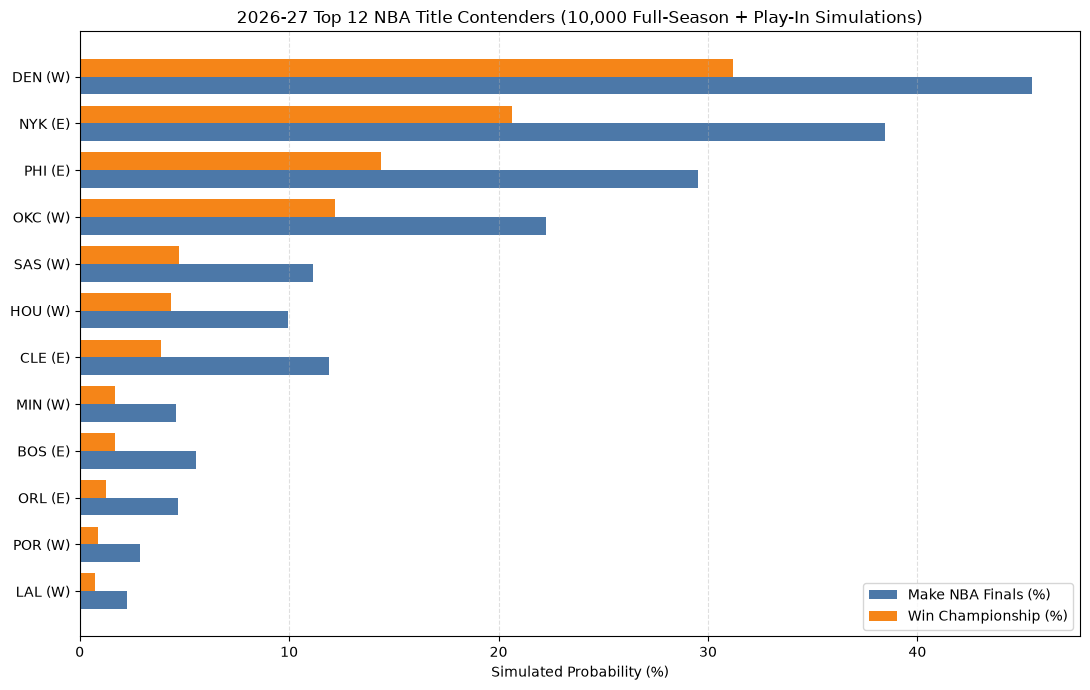

In [11]:
# visualizing NBA Finals vs. Championship probabilities for the top 12 title contenders
top_contenders = results_df.head(12).iloc[::-1]

y_pos = np.arange(len(top_contenders))
bar_height = 0.38

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(
    y_pos - bar_height / 2,
    top_contenders['FINALS_PROB'] * 100,
    height=bar_height,
    label='Make NBA Finals (%)',
    color='#4c78a8'
)
ax.barh(
    y_pos + bar_height / 2,
    top_contenders['CHAMPIONSHIP_PROB'] * 100,
    height=bar_height,
    label='Win Championship (%)',
    color='#f58518'
)

ax.set_yticks(y_pos)
ax.set_yticklabels([f"{row.TEAM} ({row.CONF[0]})" for _, row in top_contenders.iterrows()])
ax.set_xlabel('Simulated Probability (%)')
ax.set_title('2026-27 Top 12 NBA Title Contenders (10,000 Full-Season + Play-In Simulations)')
ax.legend(loc='lower right')
ax.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### 8b. Simulation Diagnostic: Regular Season Win Distribution Ranges (30 Teams)

We plot the simulated 82-game regular season win distributions across all 10,000 universes for every NBA team:
- **Thin Whiskers:** 5th to 95th percentile outcome range (floor vs. ceiling).
- **Thick Bars:** 25th to 75th percentile Interquartile Range (IQR).
- **White Points:** Median projected win total.
- **Dashed Line:** Benchmark .500 line (41-41 record).

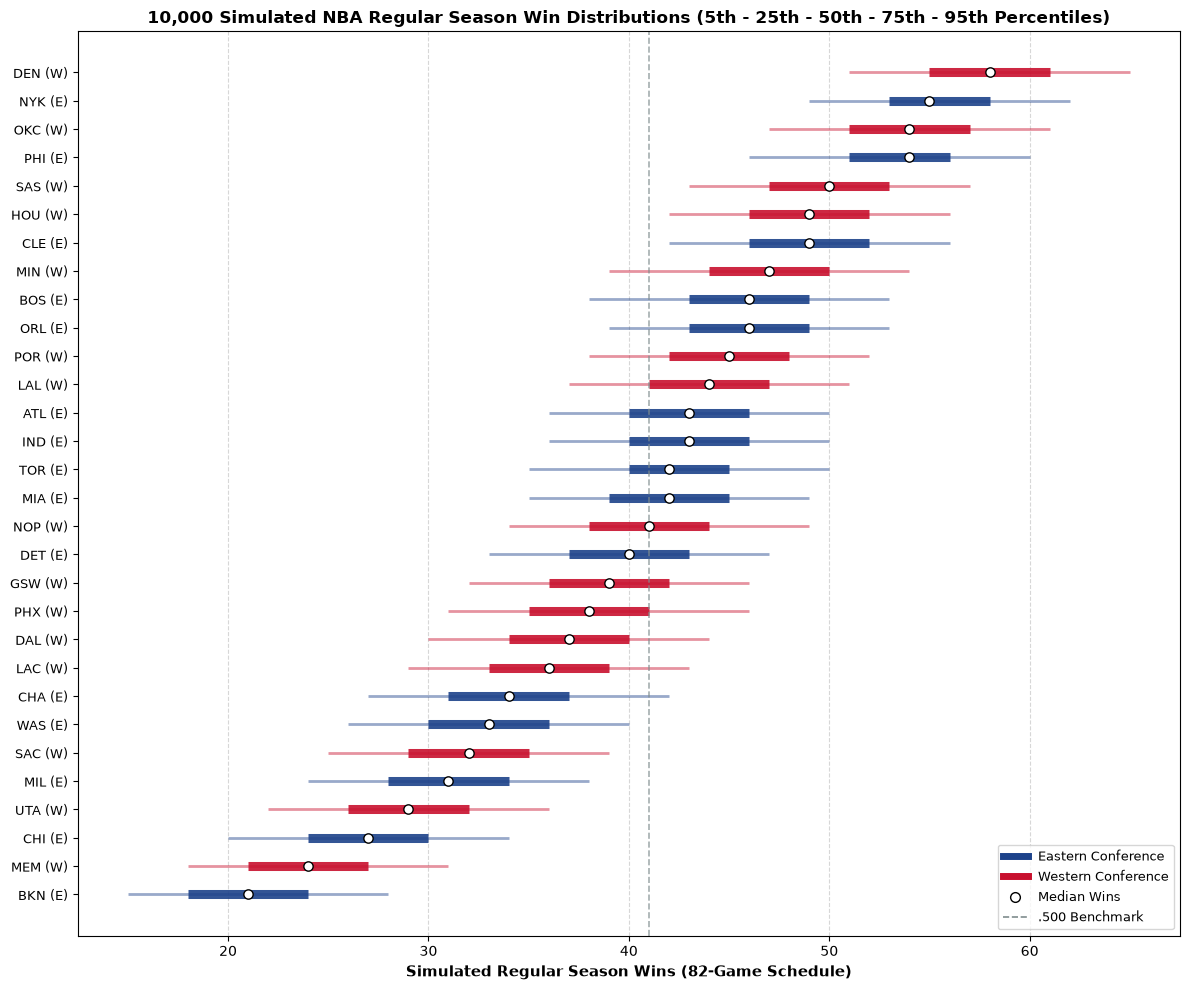

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

plt.figure(figsize=(12, 10))
conf_map = dict(zip(projected_strength['TEAM_ABBREVIATION'], projected_strength['CONFERENCE']))
median_wins = np.median(sim_reg_wins, axis=0)
order_indices = np.argsort(median_wins) # ascending for clean bottom-to-top display
sorted_teams = [all_teams_ordered[i] for i in order_indices]
sorted_conf = [conf_map[t] for t in sorted_teams]
sorted_p5 = np.percentile(sim_reg_wins, 5, axis=0)[order_indices]
sorted_p25 = np.percentile(sim_reg_wins, 25, axis=0)[order_indices]
sorted_p50 = median_wins[order_indices]
sorted_p75 = np.percentile(sim_reg_wins, 75, axis=0)[order_indices]
sorted_p95 = np.percentile(sim_reg_wins, 95, axis=0)[order_indices]

team_colors = ['#1D428A' if c == 'East' else '#C8102E' for c in sorted_conf]
y_positions = np.arange(len(sorted_teams))

# 5th-95th thin whisker
plt.hlines(y_positions, sorted_p5, sorted_p95, color=team_colors, alpha=0.45, linewidth=2.0)
# 25th-75th thick IQR bar
plt.hlines(y_positions, sorted_p25, sorted_p75, color=team_colors, alpha=0.9, linewidth=6.5)
# Median marker
plt.scatter(sorted_p50, y_positions, color='white', edgecolor='black', s=45, zorder=4)

plt.axvline(41, color='#7F8C8D', linestyle='--', linewidth=1.2, alpha=0.7, label='.500 Win Benchmark (41-41)')
plt.yticks(y_positions, [f"{t} ({c[0]})" for t, c in zip(sorted_teams, sorted_conf)], fontsize=9)
plt.xlabel('Simulated Regular Season Wins (82-Game Schedule)', fontsize=11, fontweight='bold')
plt.title('10,000 Simulated NBA Regular Season Win Distributions (5th - 25th - 50th - 75th - 95th Percentiles)', fontsize=12, fontweight='bold')
plt.grid(True, axis='x', linestyle='--', alpha=0.5)

legend_elements = [
    Line2D([0], [0], color='#1D428A', lw=5, label='Eastern Conference'),
    Line2D([0], [0], color='#C8102E', lw=5, label='Western Conference'),
    Line2D([0], [0], marker='o', color='white', markeredgecolor='black', markersize=7, label='Median Wins'),
    Line2D([0], [0], color='#7F8C8D', linestyle='--', lw=1.2, label='.500 Benchmark')
]
plt.legend(handles=legend_elements, loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

### 8c. Simulation Diagnostic: Final Calibrated Power Score Component Deconstruction

We deconstruct the final power score across all 30 teams to visualize how the three calibrated ingredients combine:
- **40% Historical Efficiency** (trained Logistic Regression win probability vs. league-average opponent)
- **50% Rotation Roster Value** (top-9 player VORP standardized via Z-score and mapped through NBA logistic spread)
- **10% Playoff Experience** (5-year postseason games played by current rosters)

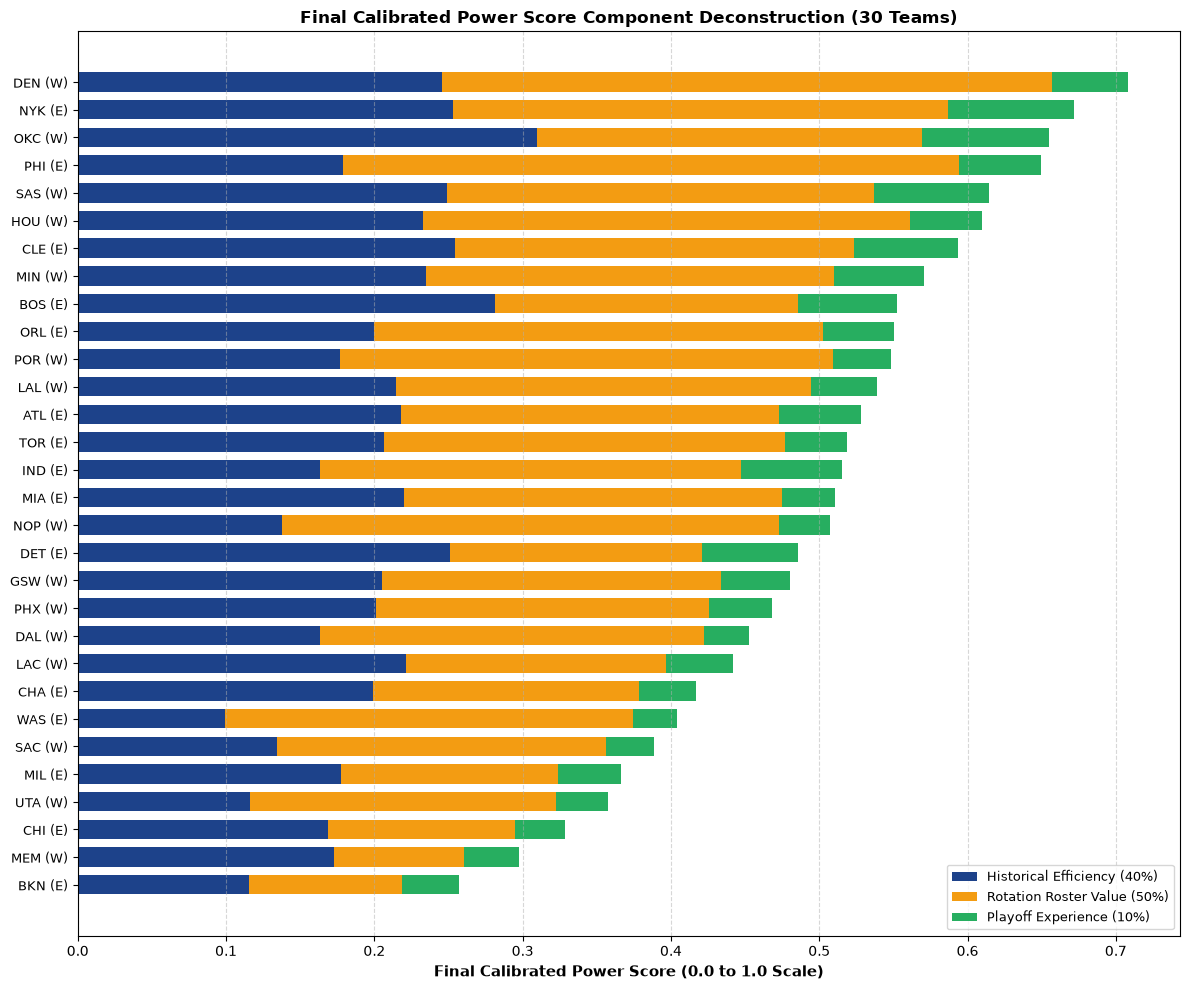

In [13]:
plt.figure(figsize=(12, 10))
ps_sorted = projected_strength.sort_values('FINAL_POWER_SCORE', ascending=True).reset_index(drop=True)
y_ps = np.arange(len(ps_sorted))

comp_hist = ps_sorted['POWER_SCORE'] * 0.40
comp_roster = ps_sorted['ROSTER_STRENGTH_PROB'] * 0.50
comp_playoff = ps_sorted['PLAYOFF_EXP_PROB'] * 0.10

plt.barh(y_ps, comp_hist, color='#1D428A', edgecolor='none', height=0.7, label='Historical Efficiency (40%)')
plt.barh(y_ps, comp_roster, left=comp_hist, color='#F39C12', edgecolor='none', height=0.7, label='Rotation Roster Value (50%)')
plt.barh(y_ps, comp_playoff, left=comp_hist + comp_roster, color='#27AE60', edgecolor='none', height=0.7, label='Playoff Experience (10%)')

plt.yticks(y_ps, [f"{row.TEAM_ABBREVIATION} ({row.CONFERENCE[0]})" for _, row in ps_sorted.iterrows()], fontsize=9)
plt.xlabel('Final Calibrated Power Score (0.0 to 1.0 Scale)', fontsize=11, fontweight='bold')
plt.title('Final Calibrated Power Score Component Deconstruction (30 Teams)', fontsize=12, fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 8. Simulation Summary & Takeaways

### Q&A
- **Who are the projected 2026-27 NBA Championship favorites across 10,000 simulated seasons?**
  **Denver (`DEN`, `31.18%`)**, **New York (`NYK`, `20.64%`)**, **Philadelphia (`PHI`, `14.37%`)**, and **Oklahoma City (`OKC`, `12.17%`)** form the primary championship contender group, followed by **San Antonio (`SAS`, `4.75%`)**, **Houston (`HOU`, `4.37%`)**, and **Cleveland (`CLE`, `3.89%`)**.
- **Why does `NYK` reach the NBA Finals at a higher rate (`38.4%`) than `OKC` (`22.3%`)?**
  Bracket structure: `DEN` (`58.1` projected wins), `OKC` (`53.9` projected wins), `SAS` (`50.0` wins), and `HOU` (`49.3` wins) must navigate a fiercely contested Western Conference playoff field, whereas `NYK` (`55.4` projected wins) and `PHI` (`53.5` projected wins) command the top tier of the Eastern Conference bracket.

### Data Analysis Key Findings
- **Empirically Calibrated Blend (Balanced Modern: 40% History / 50% Roster / 10% Playoff Exp):** Grounded in empirical Bayesian shrinkage ($K = 8.0$ games) and out-of-sample backtest validation ($8.27$ MAE across 1,230 games). Standardized via $Z$-scores and mapped through `expit(Z * 0.7204)`, producing realistic NBA win totals ranging from **58.1 wins (`DEN`)** down to **21.5 wins (`BKN`)**.
- **Play-In Bubble Dynamics (Seeds 7–10):** Full 1,230-game regular season simulation plus Play-In brackets rewards bubble contenders with authentic postseason pathways — in the East, `ORL` (`45.7W`), `ATL` (`43.2W`), `TOR` (`42.5W`), `MIA` (`42.2W`), and `IND` (`42.9W`) contend for playoff spots; in the West, `MIN` (`46.8W`), `POR` (`44.9W`), `LAL` (`43.7W`), `NOP` (`41.2W`), and `GSW` (`39.1W`) contest the Play-In bracket.

### Insights or Next Steps
- **Scope & Snapshot Reproducibility:** Projections assume neutral-court Log5 matchups and healthy 2026-27 Opening-Week rosters (`SNAPSHOT_TAG = 'opening_week_oct2026'`).
- **Future Checkpoints:** After the February 2027 trade deadline, setting `SNAPSHOT_TAG = 'trade_deadline_feb2027'` with `REFRESH_API = True` in Phase 2 will cache mid-season rosters and projections side-by-side with this October Opening-Week baseline.